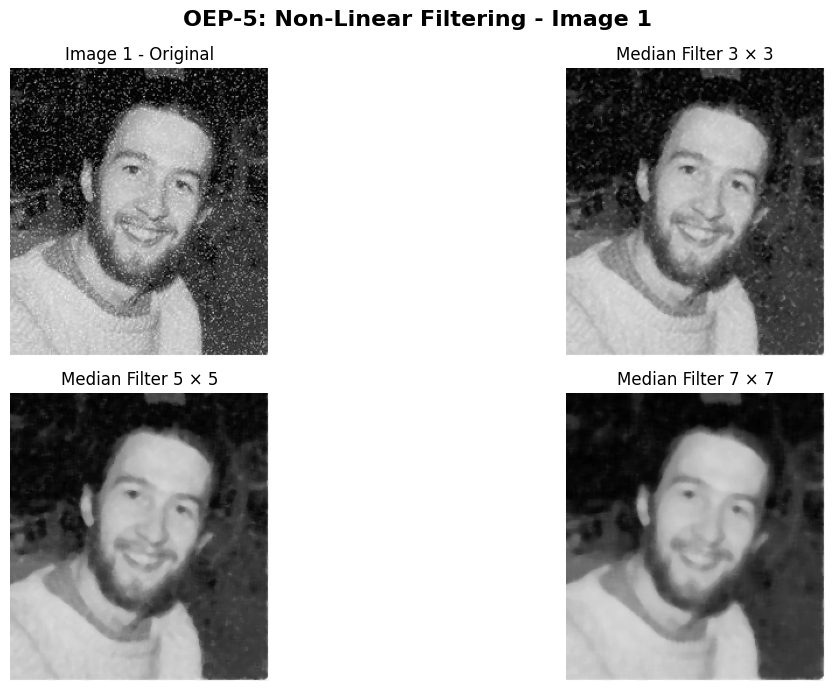

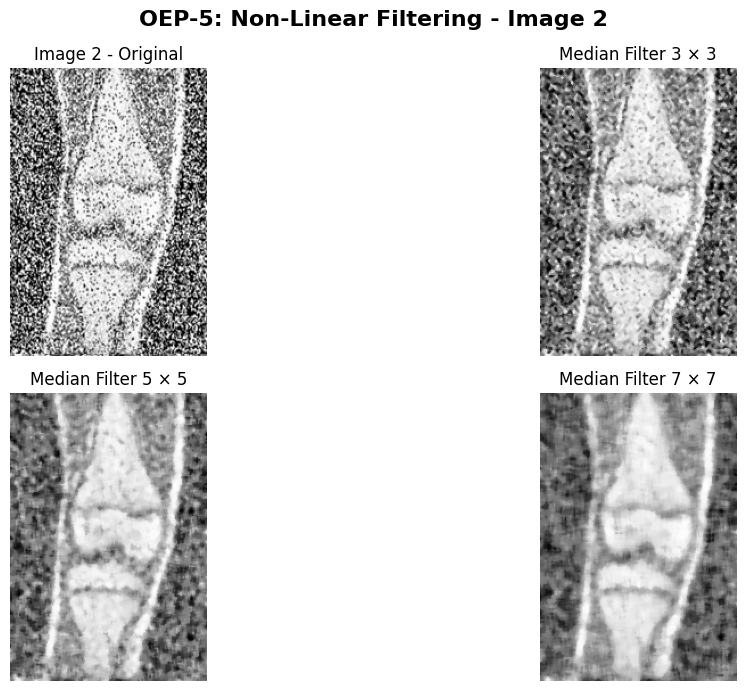

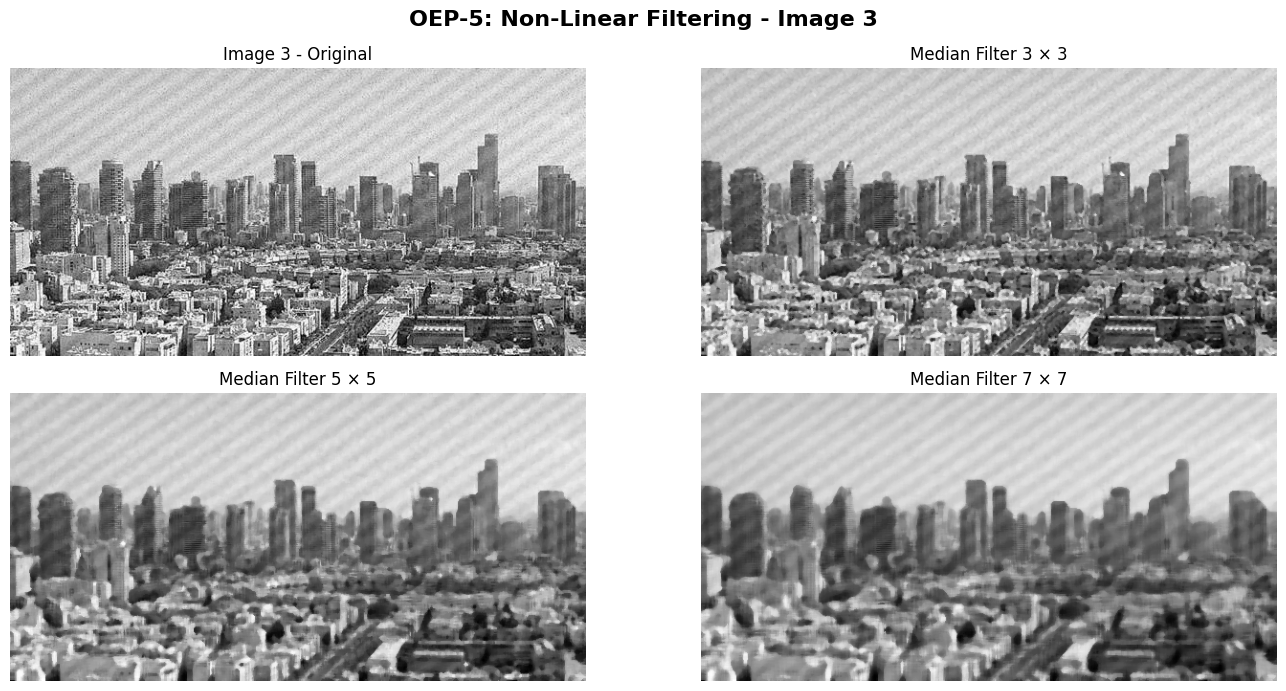

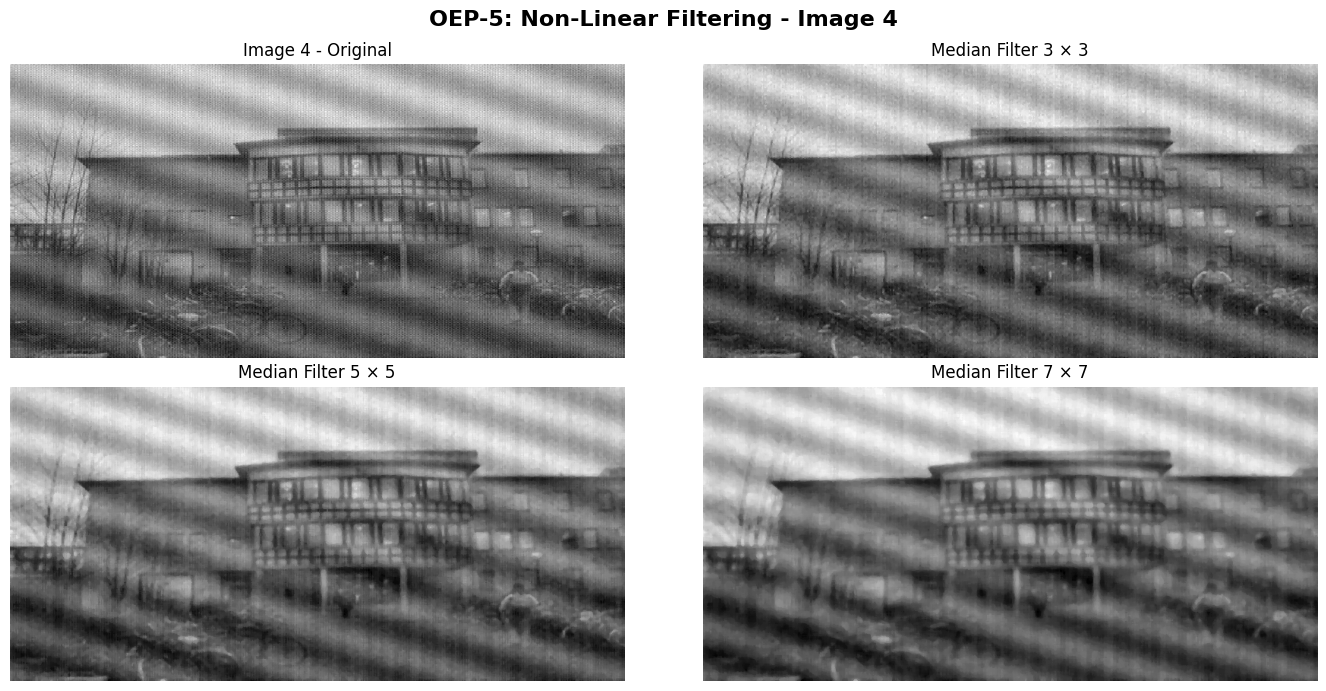

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# OEP-5: NON-LINEAR FILTERING
# Images: image1.jpeg to image4.jpeg
# ============================================================

for i in range(1, 5):

    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------
    image = cv2.imread(f"image{i}.jpeg", cv2.IMREAD_GRAYSCALE)

    if image is None:
        print(f"Error: image{i}.jpeg not found!")
        continue

    # --------------------------------------------------------
    # Median filters with different window sizes
    # --------------------------------------------------------
    median_3 = cv2.medianBlur(image, 3)
    median_5 = cv2.medianBlur(image, 5)
    median_7 = cv2.medianBlur(image, 7)

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------
    plt.figure(figsize=(14, 7))

    plt.subplot(2, 2, 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"Image {i} - Original")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(median_3, cmap="gray")
    plt.title("Median Filter 3 × 3")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(median_5, cmap="gray")
    plt.title("Median Filter 5 × 5")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(median_7, cmap="gray")
    plt.title("Median Filter 7 × 7")
    plt.axis("off")

    plt.suptitle(
        f"OEP-5: Non-Linear Filtering - Image {i}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Save filtered images
    # --------------------------------------------------------
    cv2.imwrite(f"image{i}_median3.jpg", median_3)
    cv2.imwrite(f"image{i}_median5.jpg", median_5)
    cv2.imwrite(f"image{i}_median7.jpg", median_7)

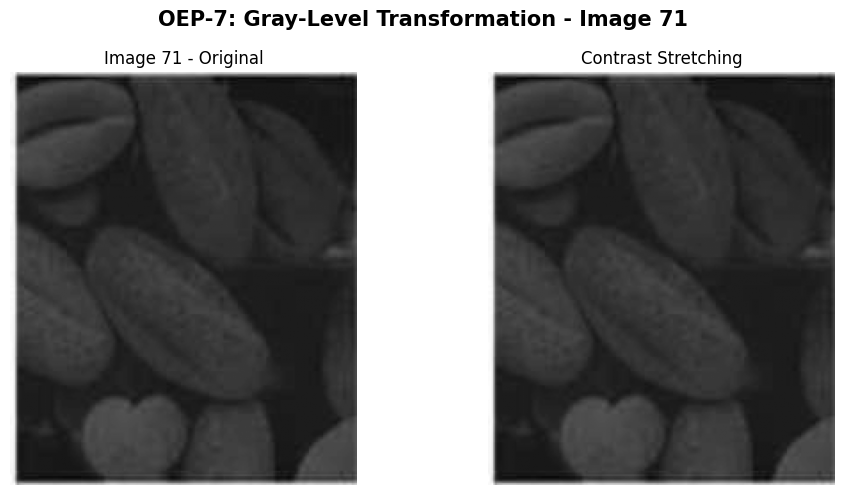

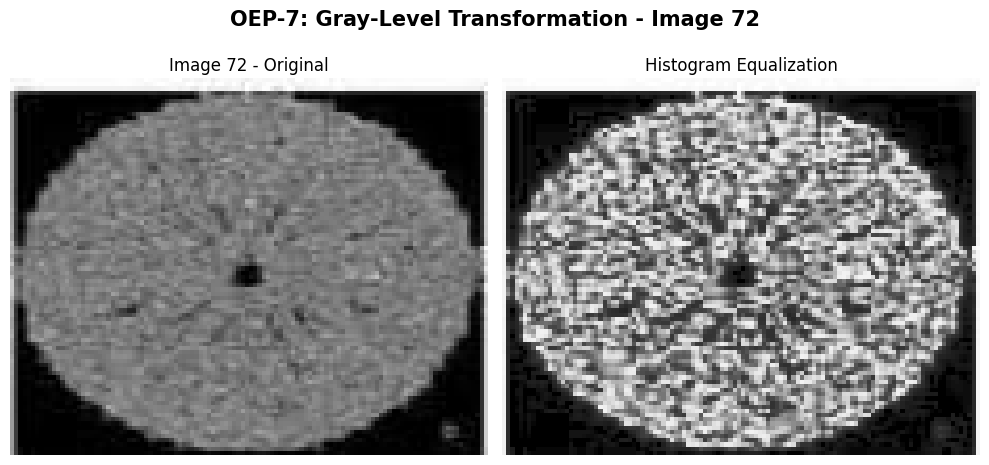

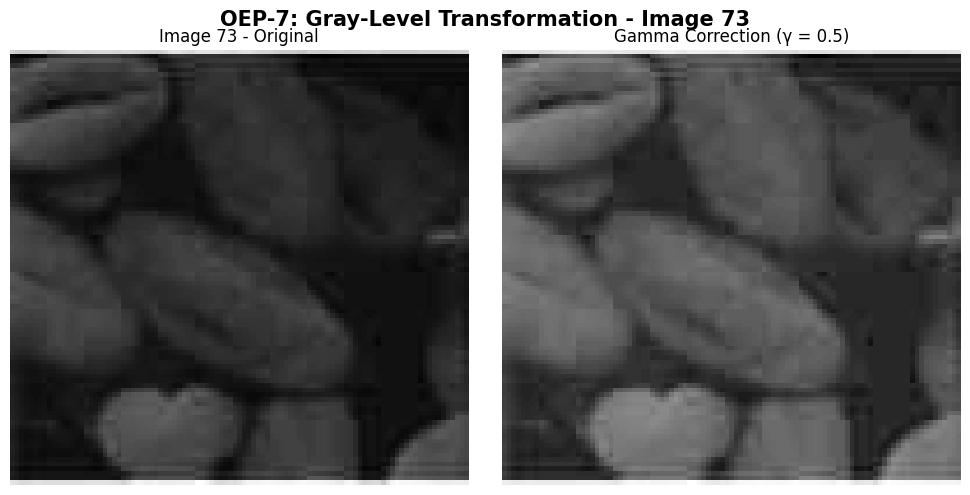

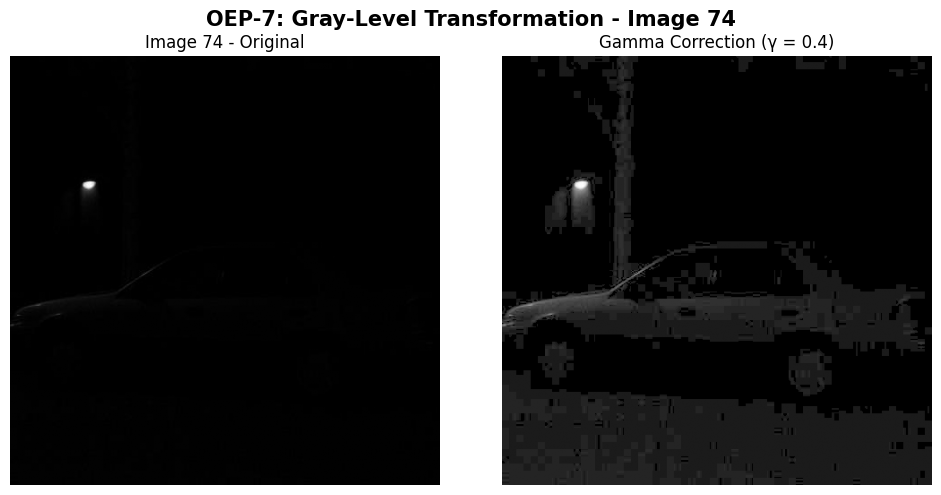

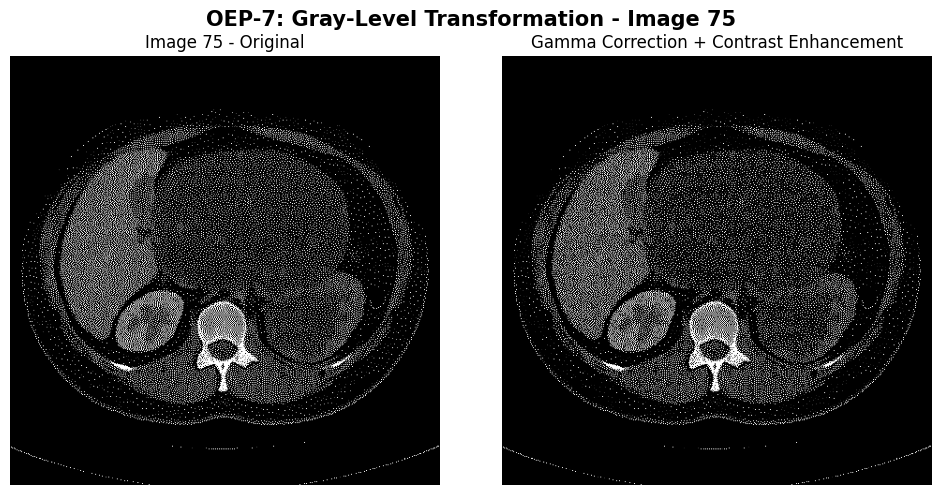

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# OEP-7: GRAY-LEVEL TRANSFORMATION
# Images: image71.jpeg to image75.jpeg
# ============================================================

for i in range(71, 76):

    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------
    image = cv2.imread(
        f"image{i}.jpeg",
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        print(f"Error: image{i}.jpeg not found!")
        continue

    # --------------------------------------------------------
    # Image 71 - Contrast Stretching
    # --------------------------------------------------------
    if i == 71:

        min_val = np.min(image)
        max_val = np.max(image)

        enhanced = cv2.normalize(
            image,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )

        method = "Contrast Stretching"

    # --------------------------------------------------------
    # Image 72 - Histogram Equalization
    # --------------------------------------------------------
    elif i == 72:

        enhanced = cv2.equalizeHist(image)

        method = "Histogram Equalization"

    # --------------------------------------------------------
    # Image 73 - Gamma Correction
    # --------------------------------------------------------
    elif i == 73:

        gamma = 0.5

        normalized = image / 255.0

        enhanced = np.uint8(
            255 * np.power(normalized, gamma)
        )

        method = "Gamma Correction (γ = 0.5)"

    # --------------------------------------------------------
    # Image 74 - Gamma Correction
    # --------------------------------------------------------
    elif i == 74:

        gamma = 0.4

        normalized = image / 255.0

        enhanced = np.uint8(
            255 * np.power(normalized, gamma)
        )

        method = "Gamma Correction (γ = 0.4)"

    # --------------------------------------------------------
    # Image 75 - Gamma + Contrast Enhancement
    # --------------------------------------------------------
    else:

        gamma = 0.3

        normalized = image / 255.0

        gamma_image = np.uint8(
            255 * np.power(normalized, gamma)
        )

        enhanced = cv2.equalizeHist(gamma_image)

        method = "Gamma Correction + Contrast Enhancement"

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"Image {i} - Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced, cmap="gray")
    plt.title(method)
    plt.axis("off")

    plt.suptitle(
        f"OEP-7: Gray-Level Transformation - Image {i}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Save enhanced image
    # --------------------------------------------------------
    cv2.imwrite(
        f"image{i}_enhanced.jpg",
        enhanced
    )


PROCESSING IMAGE 1: image1.jpeg
Estimated Noise Type : Salt-and-Pepper / Impulse Noise
Extreme Pixel Ratio  : 9.01%
Noise Estimate       : 22.10


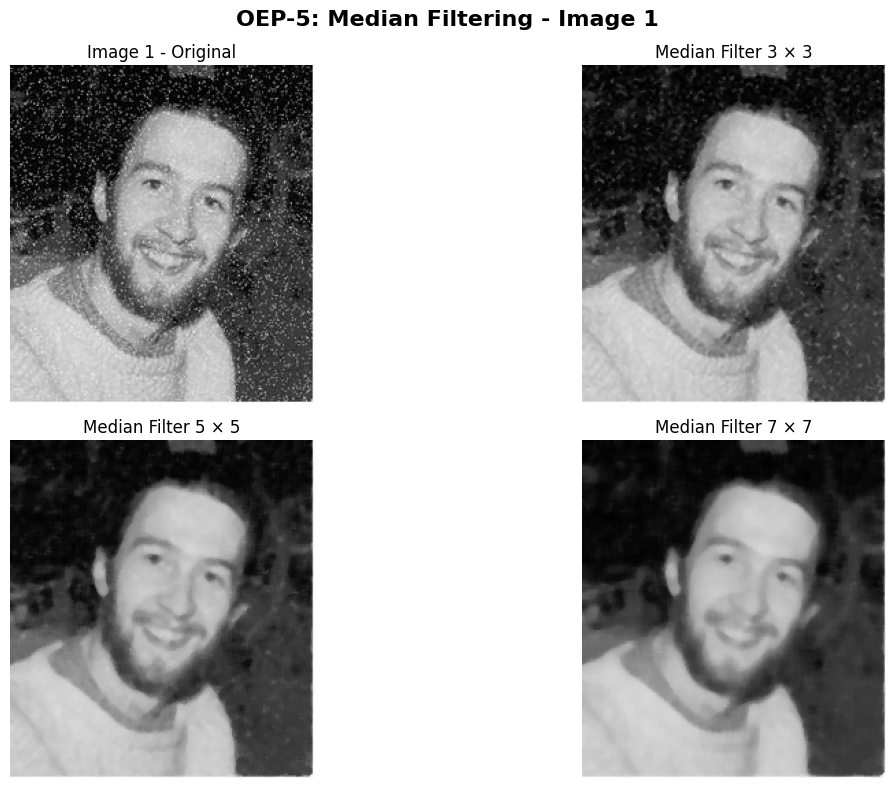

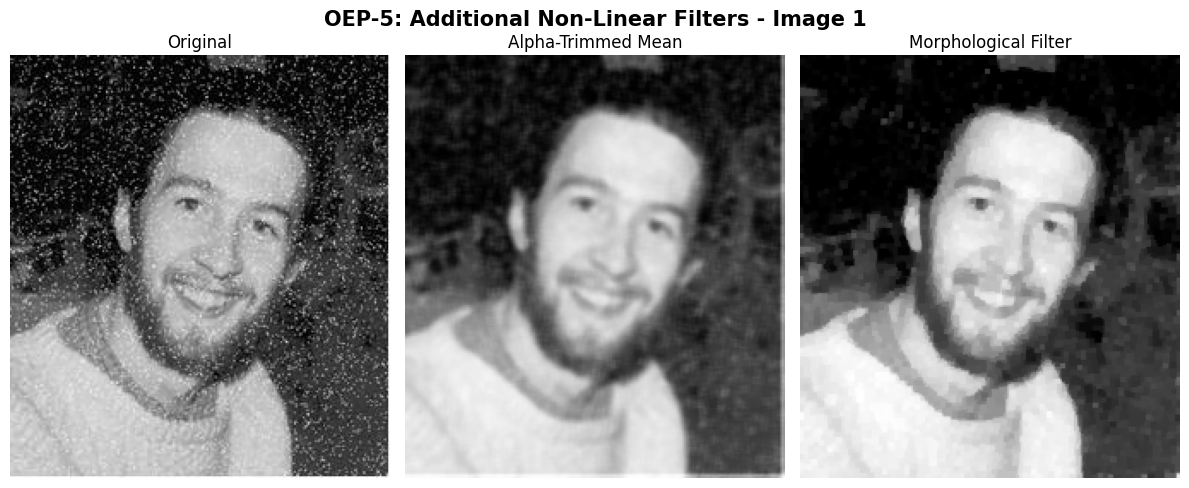


PROCESSING IMAGE 2: image2.jpeg
Estimated Noise Type : Salt-and-Pepper / Impulse Noise
Extreme Pixel Ratio  : 9.64%
Noise Estimate       : 53.07


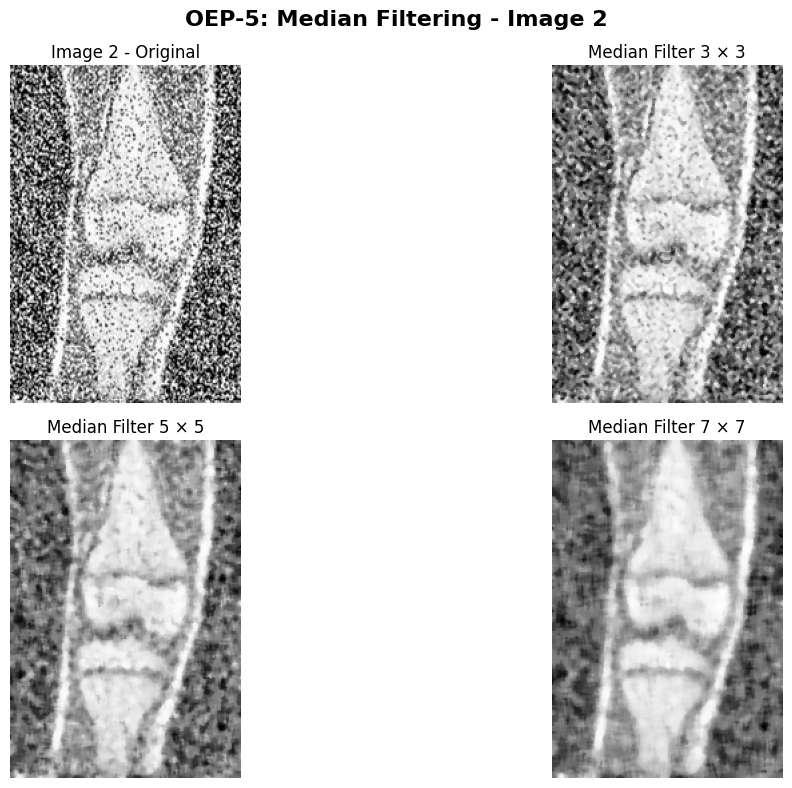

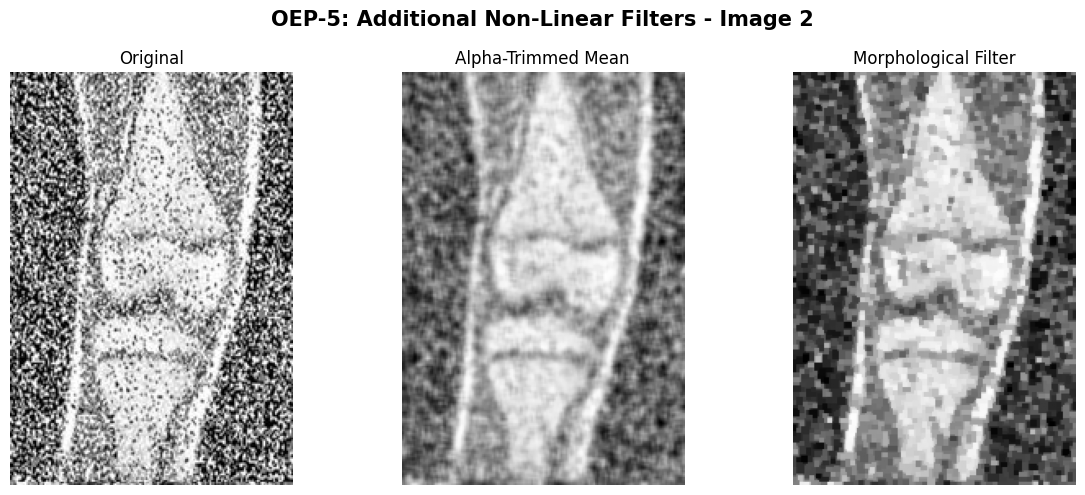


PROCESSING IMAGE 3: image3.jpeg
Estimated Noise Type : Impulse / High-Frequency Noise
Extreme Pixel Ratio  : 0.71%
Noise Estimate       : 26.93


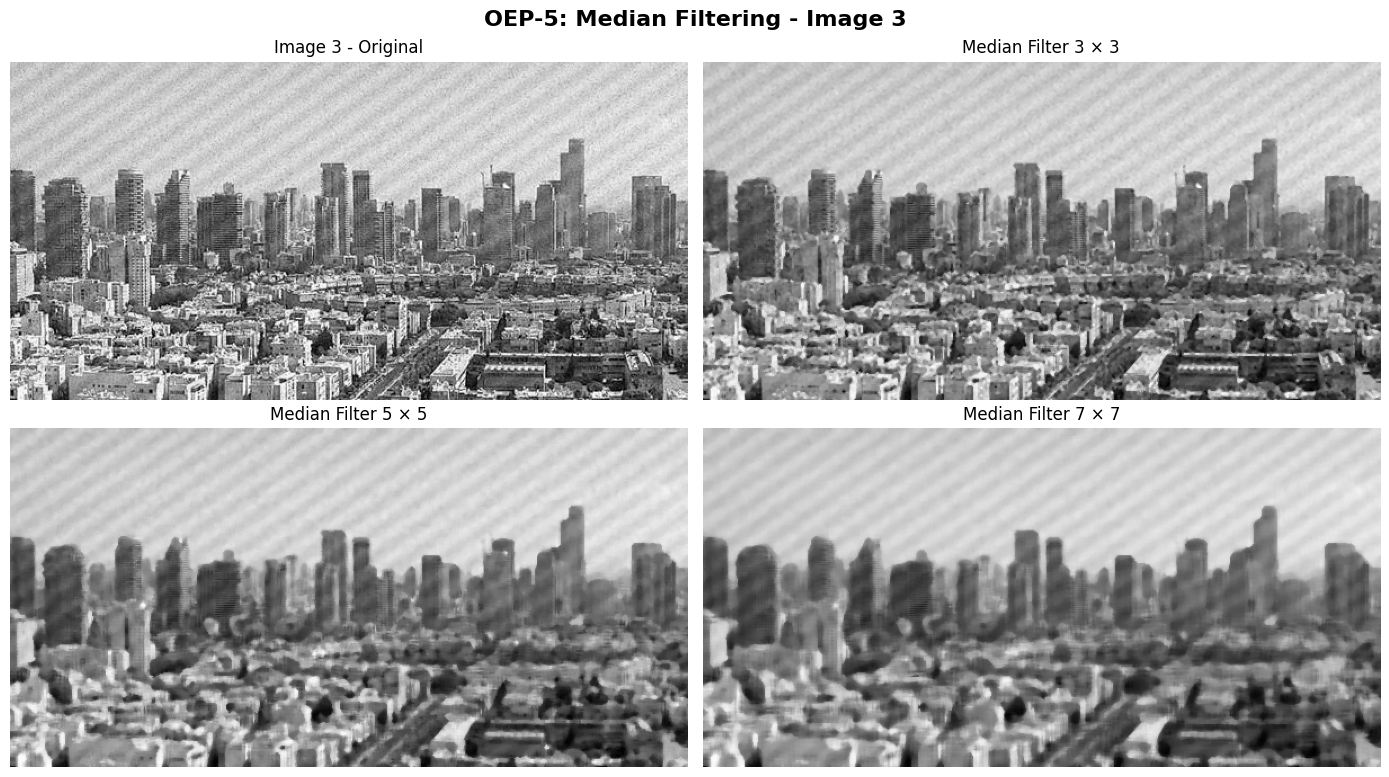

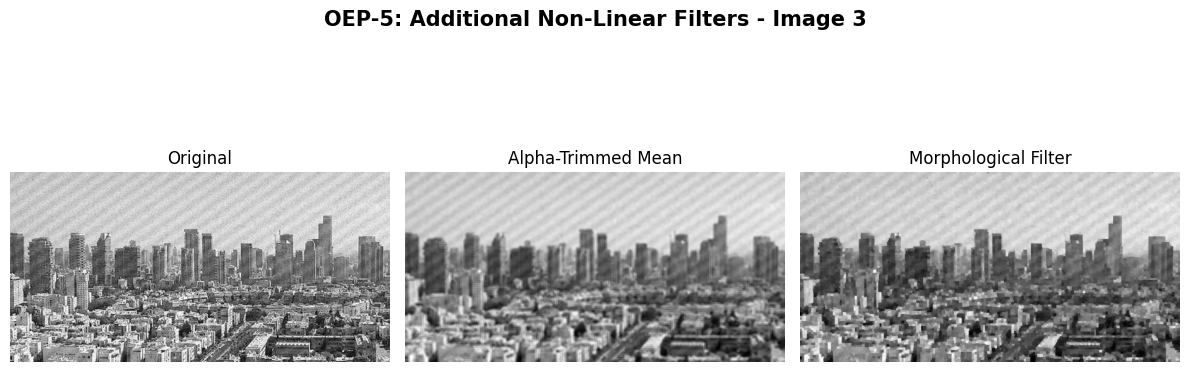


PROCESSING IMAGE 4: image4.jpeg
Estimated Noise Type : Low / Mixed Noise
Extreme Pixel Ratio  : 0.00%
Noise Estimate       : 11.64


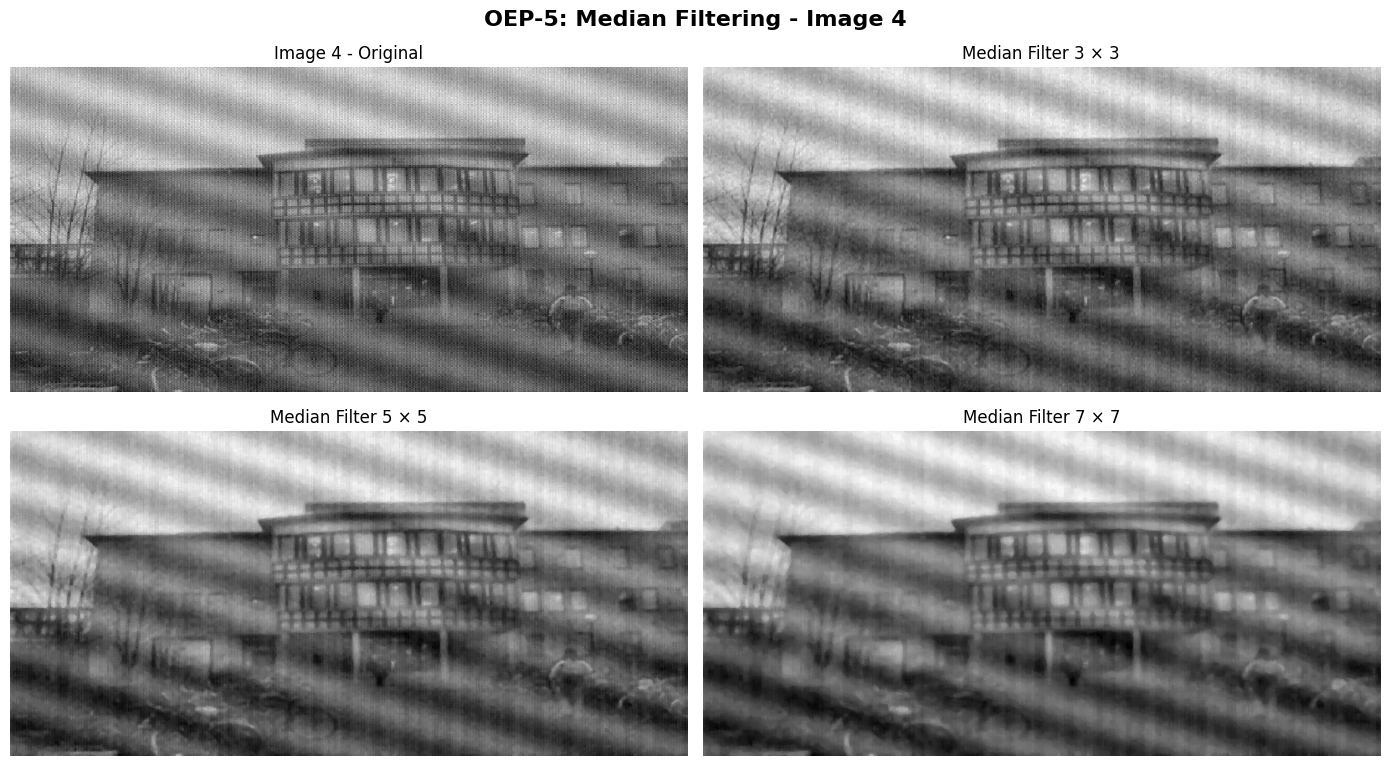

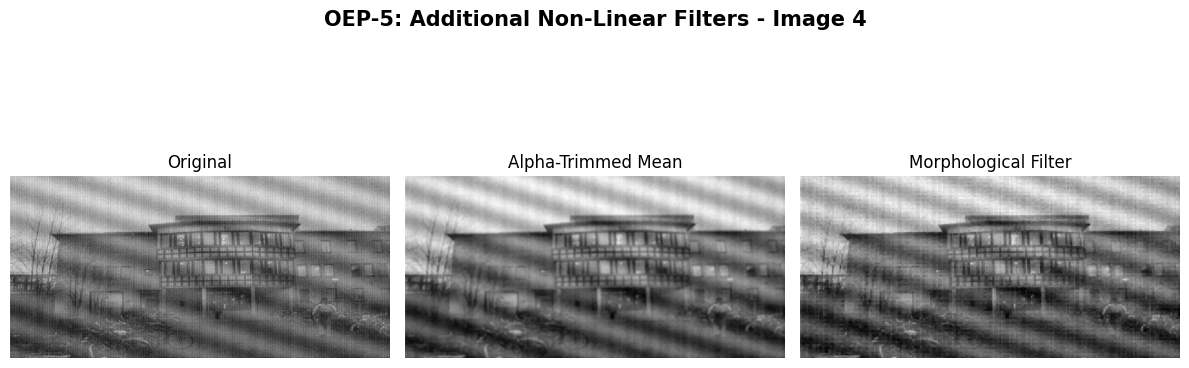



OEP-5 FILTER PERFORMANCE COMPARISON
 Image     Filter  Noise Reduction (%)  Edge Preservation (%)  Detail Preservation (%)
     1 Median 3x3            73.570000                  52.19                    44.35
     1 Median 5x5            88.610001                  21.57                    18.07
     1 Median 7x7            93.089996                  15.33                    13.03
     2 Median 3x3            62.180000                  93.59                    86.75
     2 Median 5x5            80.510002                  72.93                    62.37
     2 Median 7x7            88.080002                  48.74                    39.69
     3 Median 3x3            64.970001                  75.17                    66.63
     3 Median 5x5            80.099998                  53.36                    44.38
     3 Median 7x7            87.309998                  35.24                    28.96
     4 Median 3x3            68.620003                  19.69                    16.51
     

In [3]:
# ============================================================
# OEP-5: NON-LINEAR FILTERING FOR IMAGE NOISE REMOVAL
# ============================================================
#
# Images:
# image1.jpeg
# image2.jpeg
# image3.jpeg
# image4.jpeg
#
# Operations:
# 1. Noise identification
# 2. Median filtering: 3x3, 5x5, 7x7
# 3. Alpha-trimmed mean filtering
# 4. Morphological filtering
# 5. Edge preservation analysis
# 6. Noise reduction analysis
# 7. Best filter selection
# 8. Comparison table
# 9. Save enhanced images
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

IMAGE_FILES = [
    "image1.jpeg",
    "image2.jpeg",
    "image3.jpeg",
    "image4.jpeg"
]

FILTER_SIZES = [3, 5, 7]

# Create output folder
os.makedirs("OEP5_Output", exist_ok=True)


# ============================================================
# FUNCTION 1: LOAD IMAGE
# ============================================================

def load_image(filename):

    image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print(f"ERROR: {filename} not found!")
        return None

    return image


# ============================================================
# FUNCTION 2: NOISE IDENTIFICATION
# ============================================================

def identify_noise(image):

    total_pixels = image.size

    # Count very dark pixels
    black_pixels = np.sum(image <= 5)

    # Count very bright pixels
    white_pixels = np.sum(image >= 250)

    extreme_pixels = black_pixels + white_pixels

    extreme_percentage = (
        extreme_pixels / total_pixels
    ) * 100

    # Estimate local noise using median residual
    median_image = cv2.medianBlur(image, 5)

    residual = image.astype(np.float32) - median_image.astype(np.float32)

    noise_std = np.std(residual)

    # Estimate image variance
    image_std = np.std(image)

    # Simple classification
    if extreme_percentage > 5:
        noise_type = "Salt-and-Pepper / Impulse Noise"

    elif noise_std > 25:
        noise_type = "Impulse / High-Frequency Noise"

    elif image_std > 45:
        noise_type = "Speckle / High-Variance Noise"

    else:
        noise_type = "Low / Mixed Noise"

    return noise_type, extreme_percentage, noise_std


# ============================================================
# FUNCTION 3: ALPHA-TRIMMED MEAN FILTER
# ============================================================

def alpha_trimmed_mean(image, kernel_size=5, d=4):

    pad = kernel_size // 2

    padded = cv2.copyMakeBorder(
        image,
        pad,
        pad,
        pad,
        pad,
        cv2.BORDER_REFLECT
    )

    output = np.zeros_like(image, dtype=np.uint8)

    trim_each_side = d // 2

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            window = padded[
                i:i + kernel_size,
                j:j + kernel_size
            ]

            values = np.sort(window.flatten())

            if len(values) > d:
                values = values[
                    trim_each_side:
                    len(values) - trim_each_side
                ]

            output[i, j] = np.mean(values)

    return output


# ============================================================
# FUNCTION 4: MORPHOLOGICAL FILTER
# ============================================================

def morphological_filter(image):

    kernel = np.ones((3, 3), np.uint8)

    # Opening removes small bright noise
    opening = cv2.morphologyEx(
        image,
        cv2.MORPH_OPEN,
        kernel
    )

    # Closing fills small dark gaps
    closing = cv2.morphologyEx(
        opening,
        cv2.MORPH_CLOSE,
        kernel
    )

    return closing


# ============================================================
# FUNCTION 5: EDGE PRESERVATION
# ============================================================

def edge_preservation(original, filtered):

    original_edges = cv2.Canny(
        original,
        100,
        200
    )

    filtered_edges = cv2.Canny(
        filtered,
        100,
        200
    )

    original_count = np.sum(original_edges > 0)

    if original_count == 0:
        return 0

    # Dilate filtered edges slightly so small shifts
    # do not completely count as lost edges
    kernel = np.ones((3, 3), np.uint8)

    expanded_edges = cv2.dilate(
        filtered_edges,
        kernel
    )

    preserved = np.sum(
        (original_edges > 0) &
        (expanded_edges > 0)
    )

    percentage = (
        preserved / original_count
    ) * 100

    return percentage


# ============================================================
# FUNCTION 6: NOISE REDUCTION ESTIMATION
# ============================================================

def noise_reduction(original, filtered):

    # Median residual is used as a practical
    # high-frequency noise estimate
    original_median = cv2.medianBlur(
        original,
        3
    )

    filtered_median = cv2.medianBlur(
        filtered,
        3
    )

    original_noise = np.std(
        original.astype(np.float32) -
        original_median.astype(np.float32)
    )

    filtered_noise = np.std(
        filtered.astype(np.float32) -
        filtered_median.astype(np.float32)
    )

    if original_noise == 0:
        return 0

    reduction = (
        (original_noise - filtered_noise)
        / original_noise
    ) * 100

    return reduction


# ============================================================
# FUNCTION 7: DETAIL PRESERVATION
# ============================================================

def detail_preservation(original, filtered):

    # Compare edge information
    original_edges = cv2.Canny(
        original,
        100,
        200
    )

    filtered_edges = cv2.Canny(
        filtered,
        100,
        200
    )

    original_edges_count = np.sum(
        original_edges > 0
    )

    filtered_edges_count = np.sum(
        filtered_edges > 0
    )

    if original_edges_count == 0:
        return 0

    ratio = (
        filtered_edges_count /
        original_edges_count
    ) * 100

    # Avoid unrealistic values
    return min(ratio, 100)


# ============================================================
# MAIN PROCESSING
# ============================================================

all_results = []


for image_number, filename in enumerate(
    IMAGE_FILES,
    start=1
):

    print("\n" + "=" * 70)
    print(f"PROCESSING IMAGE {image_number}: {filename}")
    print("=" * 70)

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    image = load_image(filename)

    if image is None:
        continue

    # --------------------------------------------------------
    # Identify noise
    # --------------------------------------------------------

    noise_type, extreme_percentage, noise_std = \
        identify_noise(image)

    print(f"Estimated Noise Type : {noise_type}")
    print(
        f"Extreme Pixel Ratio  : "
        f"{extreme_percentage:.2f}%"
    )
    print(
        f"Noise Estimate       : "
        f"{noise_std:.2f}"
    )

    # --------------------------------------------------------
    # Median Filters
    # --------------------------------------------------------

    median_results = {}

    for size in FILTER_SIZES:

        filtered = cv2.medianBlur(
            image,
            size
        )

        median_results[size] = filtered

        # Save image
        output_name = (
            f"OEP5_Output/"
            f"image{image_number}_"
            f"median_{size}x{size}.jpg"
        )

        cv2.imwrite(
            output_name,
            filtered
        )

        # Metrics
        edge_score = edge_preservation(
            image,
            filtered
        )

        noise_score = noise_reduction(
            image,
            filtered
        )

        detail_score = detail_preservation(
            image,
            filtered
        )

        all_results.append({
            "Image": image_number,
            "Filter": f"Median {size}x{size}",
            "Noise Reduction (%)":
                round(noise_score, 2),
            "Edge Preservation (%)":
                round(edge_score, 2),
            "Detail Preservation (%)":
                round(detail_score, 2)
        })

    # --------------------------------------------------------
    # Alpha-Trimmed Mean
    # --------------------------------------------------------

    alpha_filtered = alpha_trimmed_mean(
        image,
        kernel_size=5,
        d=4
    )

    cv2.imwrite(
        f"OEP5_Output/"
        f"image{image_number}_"
        f"alpha_trimmed.jpg",
        alpha_filtered
    )

    # --------------------------------------------------------
    # Morphological Filter
    # --------------------------------------------------------

    morph_filtered = morphological_filter(
        image
    )

    cv2.imwrite(
        f"OEP5_Output/"
        f"image{image_number}_"
        f"morphological.jpg",
        morph_filtered
    )

    # --------------------------------------------------------
    # Display Median Comparison
    # --------------------------------------------------------

    plt.figure(figsize=(14, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(image, cmap="gray")
    plt.title(
        f"Image {image_number} - Original"
    )
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(
        median_results[3],
        cmap="gray"
    )
    plt.title("Median Filter 3 × 3")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(
        median_results[5],
        cmap="gray"
    )
    plt.title("Median Filter 5 × 5")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(
        median_results[7],
        cmap="gray"
    )
    plt.title("Median Filter 7 × 7")
    plt.axis("off")

    plt.suptitle(
        f"OEP-5: Median Filtering - Image {image_number}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Display Additional Filters
    # --------------------------------------------------------

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(
        image,
        cmap="gray"
    )
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(
        alpha_filtered,
        cmap="gray"
    )
    plt.title("Alpha-Trimmed Mean")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(
        morph_filtered,
        cmap="gray"
    )
    plt.title("Morphological Filter")
    plt.axis("off")

    plt.suptitle(
        f"OEP-5: Additional Non-Linear Filters - Image {image_number}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(all_results)

print("\n")
print("=" * 90)
print("OEP-5 FILTER PERFORMANCE COMPARISON")
print("=" * 90)

print(results_df.to_string(index=False))


# ============================================================
# SELECT BEST MEDIAN FILTER
# ============================================================

print("\n")
print("=" * 70)
print("RECOMMENDED MEDIAN FILTER")
print("=" * 70)

for image_number in range(1, 5):

    image_results = results_df[
        results_df["Image"] == image_number
    ]

    # Practical score:
    # noise reduction + edge/detail preservation
    image_results = image_results.copy()

    image_results["Score"] = (
        0.5 *
        image_results["Noise Reduction (%)"]
        +
        0.5 *
        image_results["Edge Preservation (%)"]
    )

    best = image_results.loc[
        image_results["Score"].idxmax()
    ]

    print(
        f"Image {image_number}: "
        f"{best['Filter']} "
        f"(Score = {best['Score']:.2f})"
    )


# ============================================================
# SAVE COMPLETE RESULTS TABLE
# ============================================================

results_df.to_csv(
    "OEP5_Output/filter_results.csv",
    index=False
)

print("\nResults saved to:")
print("OEP5_Output/filter_results.csv")

print("\nOEP-5 processing completed successfully!")